# AIR-SHIELD — 04: Pollution Driver Analysis


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os
from sklearn.ensemble import RandomForestRegressor

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False
    print("shap not installed — this notebook will fall back to built-in feature_importances_ only.")

plt.rcParams["figure.figsize"] = (10, 8)

MODEL_DIR = "D:\\AI_EDUCATOR\\Project\\AIR_SHIELD\\AIR_SHIELD\\models"
CLEAN_PATH = "D:\\AI_EDUCATOR\\Project\\AIR_SHIELD\\AIR_SHIELD\\data\\processed\\cleaned_air_quality.csv"


c:\Users\rithi\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the trained model, feature list, and data

In [3]:
best_model = joblib.load(f"{MODEL_DIR}/best_forecast_model.pkl")
FEATURES = joblib.load(f"{MODEL_DIR}/forecast_features.pkl")

df = pd.read_csv(CLEAN_PATH, parse_dates=["Date"])
print("Model:", type(best_model).__name__)
print("Number of features:", len(FEATURES))


Model: GradientBoostingRegressor
Number of features: 28


## 2. Rebuild the same feature matrix used for training

In [4]:
pollutant_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO",
                  "SO2", "O3", "Benzene", "Toluene", "Xylene"]
pollutant_cols = [c for c in pollutant_cols if c in df.columns]
FEATURE_SRC_COLS = pollutant_cols + ["AQI"]
LAGS = [1, 2, 3, 7]
ROLL_WINDOWS = [3, 7, 14]

def add_time_series_features(g):
    g = g.copy()
    for col in FEATURE_SRC_COLS:
        for lag in LAGS:
            g[f"{col}_lag{lag}"] = g[col].shift(lag)
        for win in ROLL_WINDOWS:
            g[f"{col}_roll{win}_mean"] = g[col].shift(1).rolling(win).mean()
    return g

df = pd.read_csv(CLEAN_PATH, parse_dates=["Date"]).sort_values(["City", "Date"])
df = df.groupby("City", group_keys=False).apply(add_time_series_features).reset_index()
df_with_city = df.copy()

encode_cols = [col for col in ["Season", "DayOfWeek", "City"] if col in df.columns]
prefix_map = {col: col for col in encode_cols}
df_encoded = pd.get_dummies(df, columns=encode_cols, drop_first=True, prefix=prefix_map)

FEATURES = [c for c in df_encoded.columns 
            if "_lag" in c or "_roll" in c 
            or c.startswith("Season_") or c.startswith("DayOfWeek_") 
            or c.startswith("City_") or c in ["Month","Day"]]

X_all = df_encoded.reindex(columns=FEATURES).dropna()
y_all = df_encoded.loc[X_all.index, "AQI"]

print("Rows available for modeling:", X_all.shape[0], " | Features:", len(FEATURES))

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_all, y_all)

print("Train R²:", model.score(X_all, y_all))      

Rows available for modeling: 29167  | Features: 74
Train R²: 0.9822064968234421


## 3. Built-in feature importance

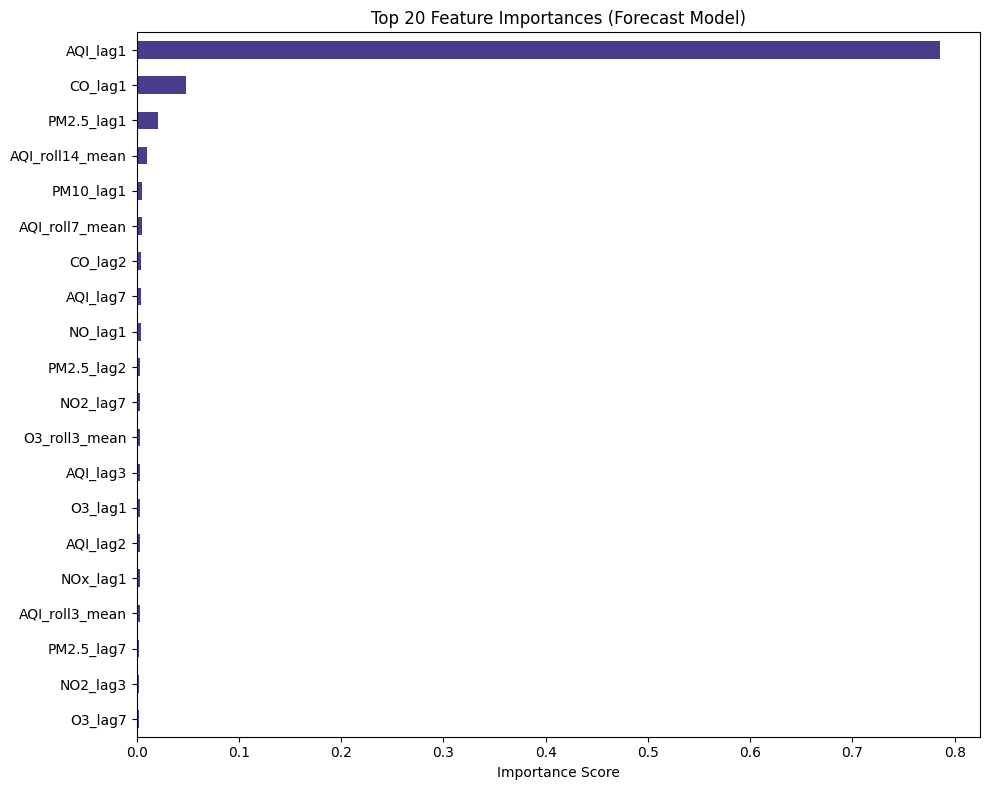

AQI_lag1           0.785522
CO_lag1            0.048478
PM2.5_lag1         0.021266
AQI_roll14_mean    0.009799
PM10_lag1          0.005096
AQI_roll7_mean     0.004901
CO_lag2            0.004531
AQI_lag7           0.003992
NO_lag1            0.003980
PM2.5_lag2         0.003719
NO2_lag7           0.003588
O3_roll3_mean      0.003548
AQI_lag3           0.003425
O3_lag1            0.003171
AQI_lag2           0.003036
NOx_lag1           0.002965
AQI_roll3_mean     0.002954
PM2.5_lag7         0.002780
NO2_lag3           0.002773
O3_lag7            0.002729
dtype: float64


In [5]:
importance = pd.Series(
    model.feature_importances_,
    index=X_all.columns
).sort_values(ascending=False)

top20 = importance.head(20)

plt.figure(figsize=(10, 8))
top20.sort_values().plot(
    kind="barh",
    color="darkslateblue"
)

plt.title("Top 20 Feature Importances (Forecast Model)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

importance.to_csv(
    "../data/processed/feature_importance.csv",
    header=["importance"]
)

print(top20)

## 4. SHAP explainability

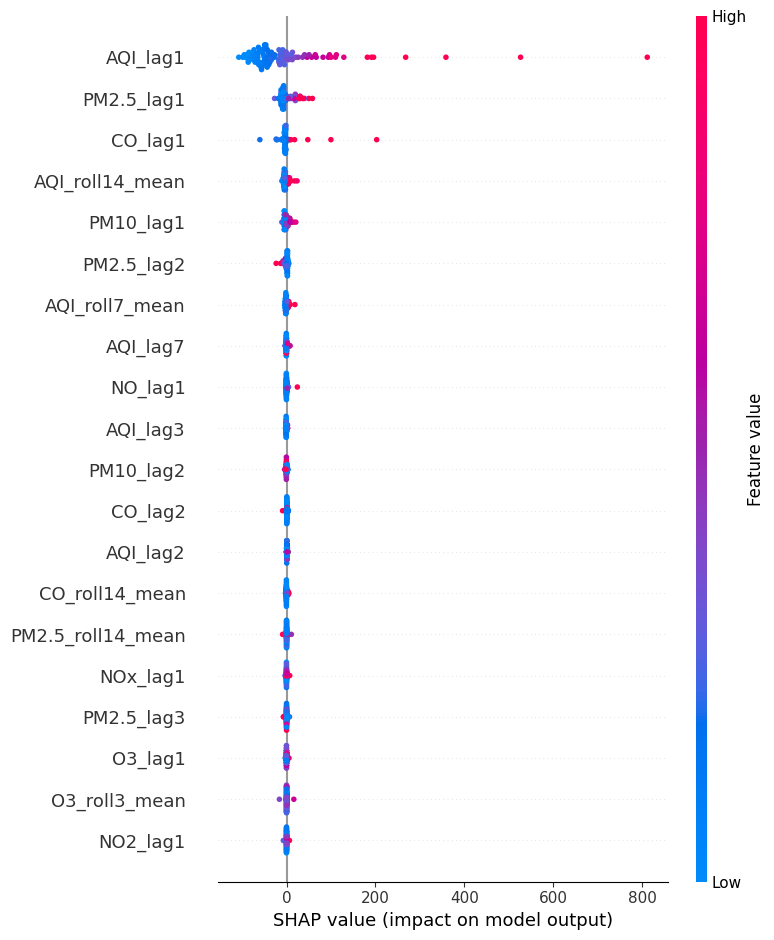

In [6]:
if HAS_SHAP:

    X_shap = X_all.copy()

    X_shap = X_shap.apply(
        pd.to_numeric,
        errors="coerce"
    )

    X_shap = X_shap.dropna()

    sample = X_shap.sample(
        min(100, len(X_shap)),
        random_state=42
    )

    explainer = shap.TreeExplainer(model)

    shap_values = explainer.shap_values(sample)

    shap.summary_plot(
        shap_values,
        sample,
        show=True
    )

else:
    print(
        "Install shap (pip install shap) to run this section. "
        "Feature importance can be used as a fallback."
    )


## 5. Reduce to top pollutant drivers 

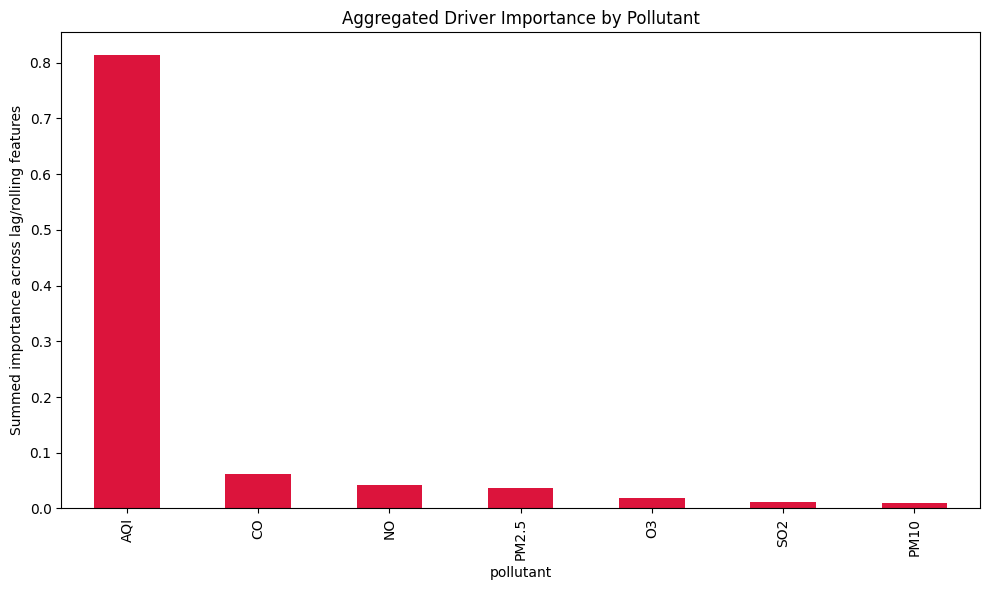

pollutant
AQI      0.813629
CO       0.062124
NO       0.041386
PM2.5    0.036968
O3       0.018700
SO2      0.012296
PM10     0.009995
Name: importance, dtype: float64

In [7]:
def base_pollutant(feature_name):
    for p in pollutant_cols + ["AQI"]:
        if feature_name.startswith(p):
            return p
    return None

importance_by_pollutant = (
    importance.rename_axis("feature").reset_index(name="importance")
    .assign(pollutant=lambda d: d["feature"].apply(base_pollutant))
    .dropna(subset=["pollutant"])
    .groupby("pollutant")["importance"].sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
importance_by_pollutant.plot(kind="bar", color="crimson")
plt.title("Aggregated Driver Importance by Pollutant")
plt.ylabel("Summed importance across lag/rolling features")
plt.tight_layout()
plt.show()

importance_by_pollutant


## 6. Per-city driver summary for the dashboard

In [11]:
original_df = pd.read_csv(
    CLEAN_PATH,
    parse_dates=["Date"]
)

latest_by_city = (
    original_df
    .sort_values("Date")
    .groupby("City")
    .tail(1)
)

driver_rows = []

for _, row in latest_by_city.iterrows():

    city_scores = {}

    for p in importance_by_pollutant.index:

        if (
            p in row.index
            and pd.notna(row[p])
        ):

            city_scores[p] = (
                importance_by_pollutant[p] * row[p]
            )

    if city_scores:

        driver_rows.append({
            "City": row["City"],
            "Date": row["Date"],
            "Top_Driver": max(
                city_scores,
                key=city_scores.get
            ),
            "Top_3_Drivers": ", ".join(
                sorted(
                    city_scores,
                    key=city_scores.get,
                    reverse=True
                )[:3]
            )
        })

driver_summary = pd.DataFrame(driver_rows)

driver_summary.to_csv(
    "../data/processed/pollution_driver_summary.csv",
    index=False
)

display(driver_summary.head(15))

,City,Date,Top_Driver,Top_3_Drivers
0,Guwahati,2020-07-01,AQI,"AQI, PM2.5, PM10"
1,Aizawl,2020-07-01,AQI,"AQI, NO, PM2.5"
2,Hyderabad,2020-07-01,AQI,"AQI, PM2.5, PM10"
3,Gurugram,2020-07-01,AQI,"AQI, PM2.5, PM10"
4,Jaipur,2020-07-01,AQI,"AQI, PM2.5, PM10"
5,Ernakulam,2020-07-01,AQI,"AQI, O3, PM2.5"
6,Delhi,2020-07-01,AQI,"AQI, PM2.5, PM10"
7,Jorapokhar,2020-07-01,AQI,"AQI, PM10, PM2.5"
8,Kochi,2020-07-01,AQI,"AQI, NO, SO2"
9,Kolkata,2020-07-01,AQI,"AQI, PM2.5, PM10"
